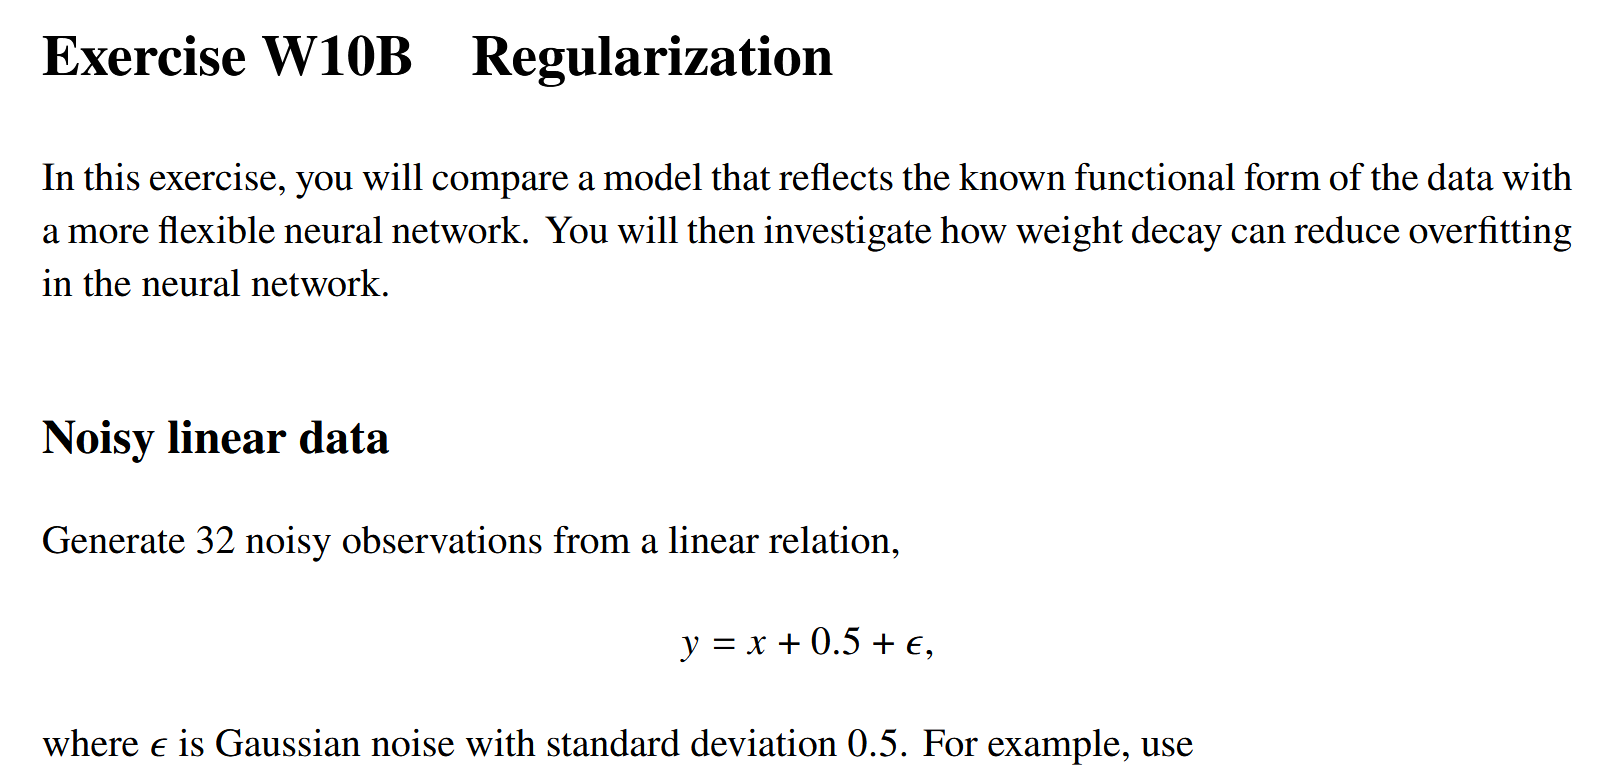
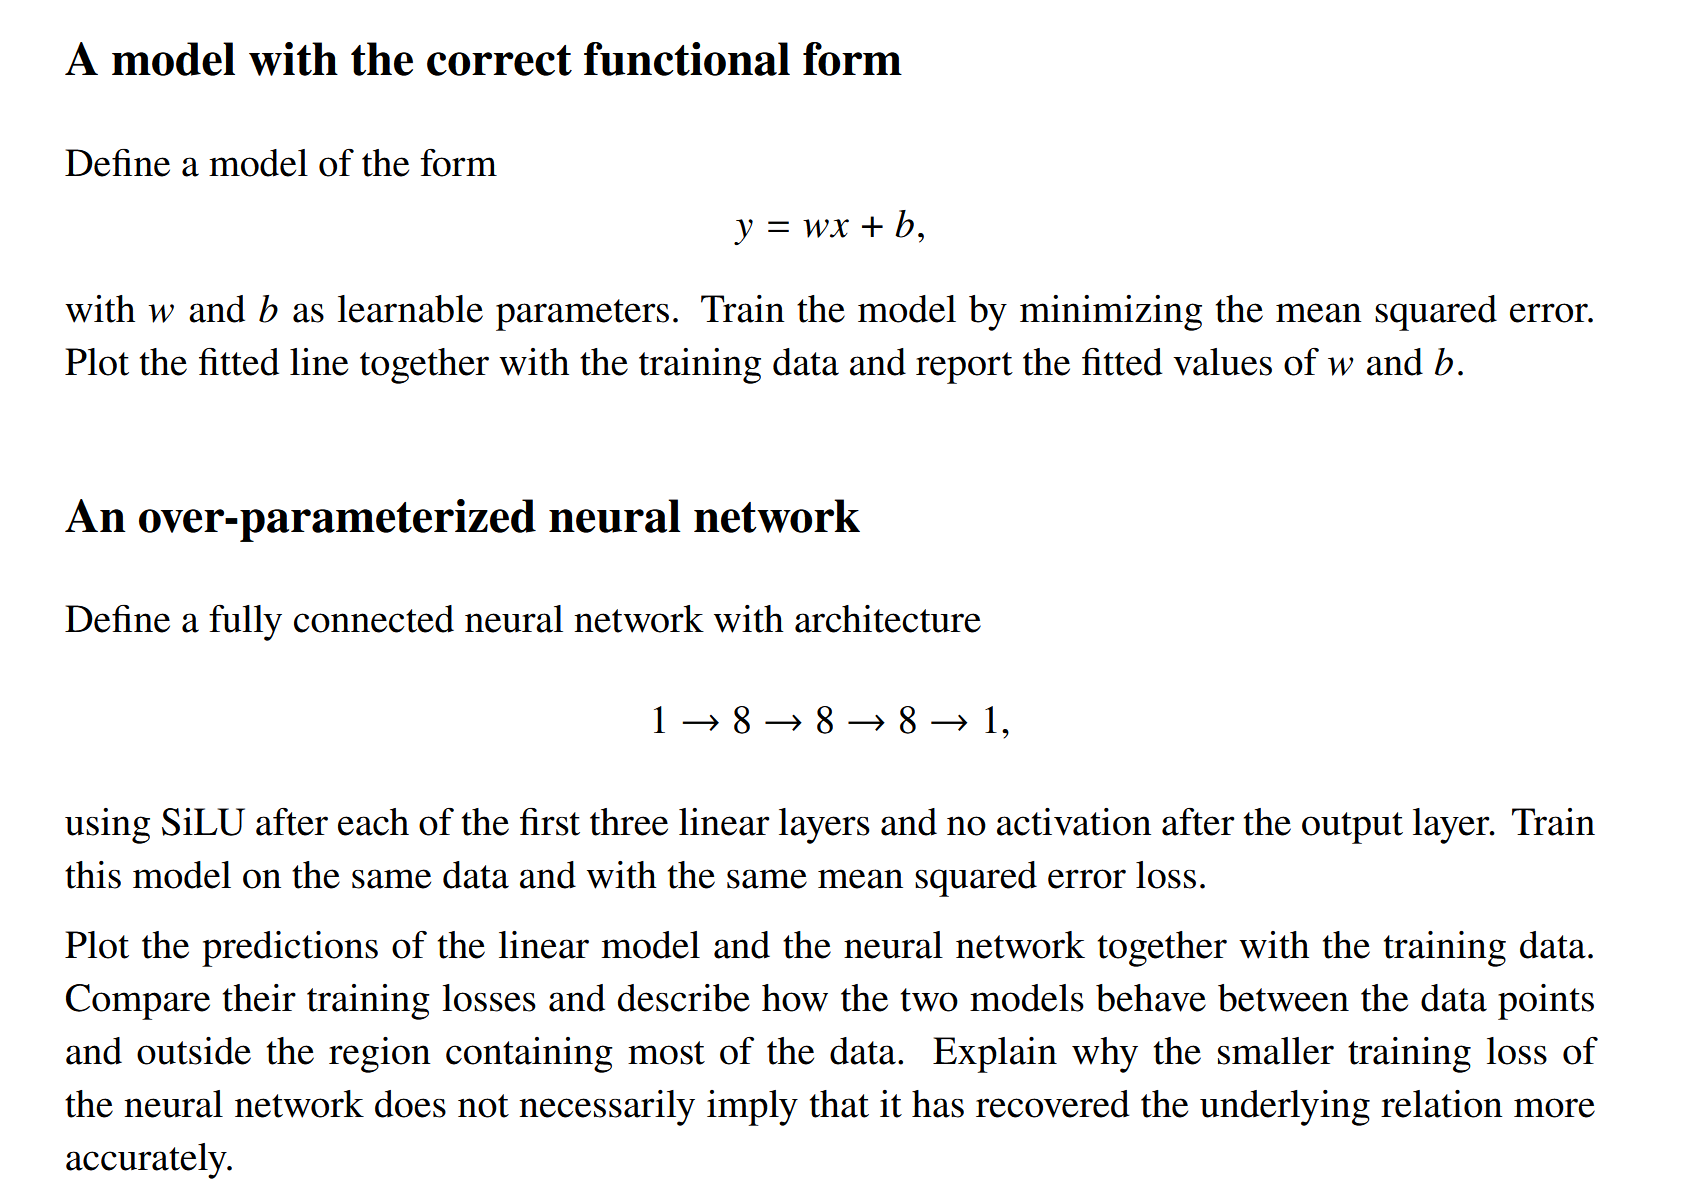

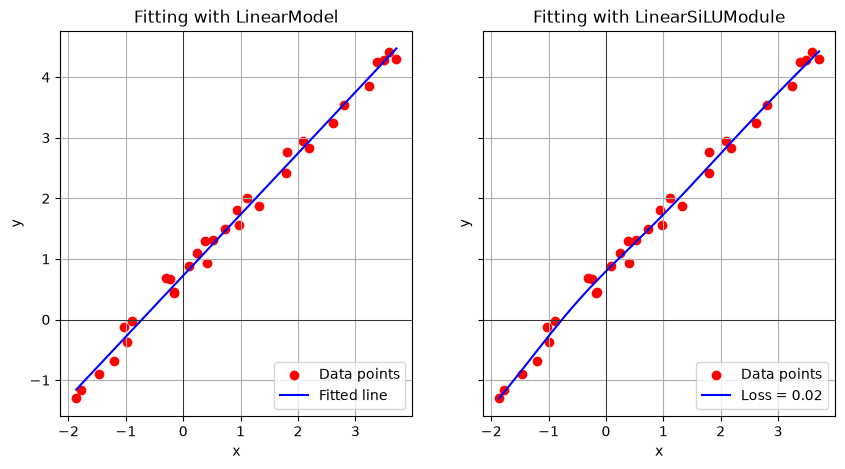

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

from models import *

torch.manual_seed(0)
xs = torch.rand(32) * 6 - 2
ys = xs + 0.5 + 0.5 * torch.rand(32)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), sharey=True)

model1 = LinearModel()
model2 = LinearSiLUModule(hidden=8, layers=2)

model1.fit(xs, ys)
model2.fit(xs, ys, epochs=1_000, lr=0.01)

model1.plot(ax1, xs, ys)
model2.plot(ax2, xs, ys)

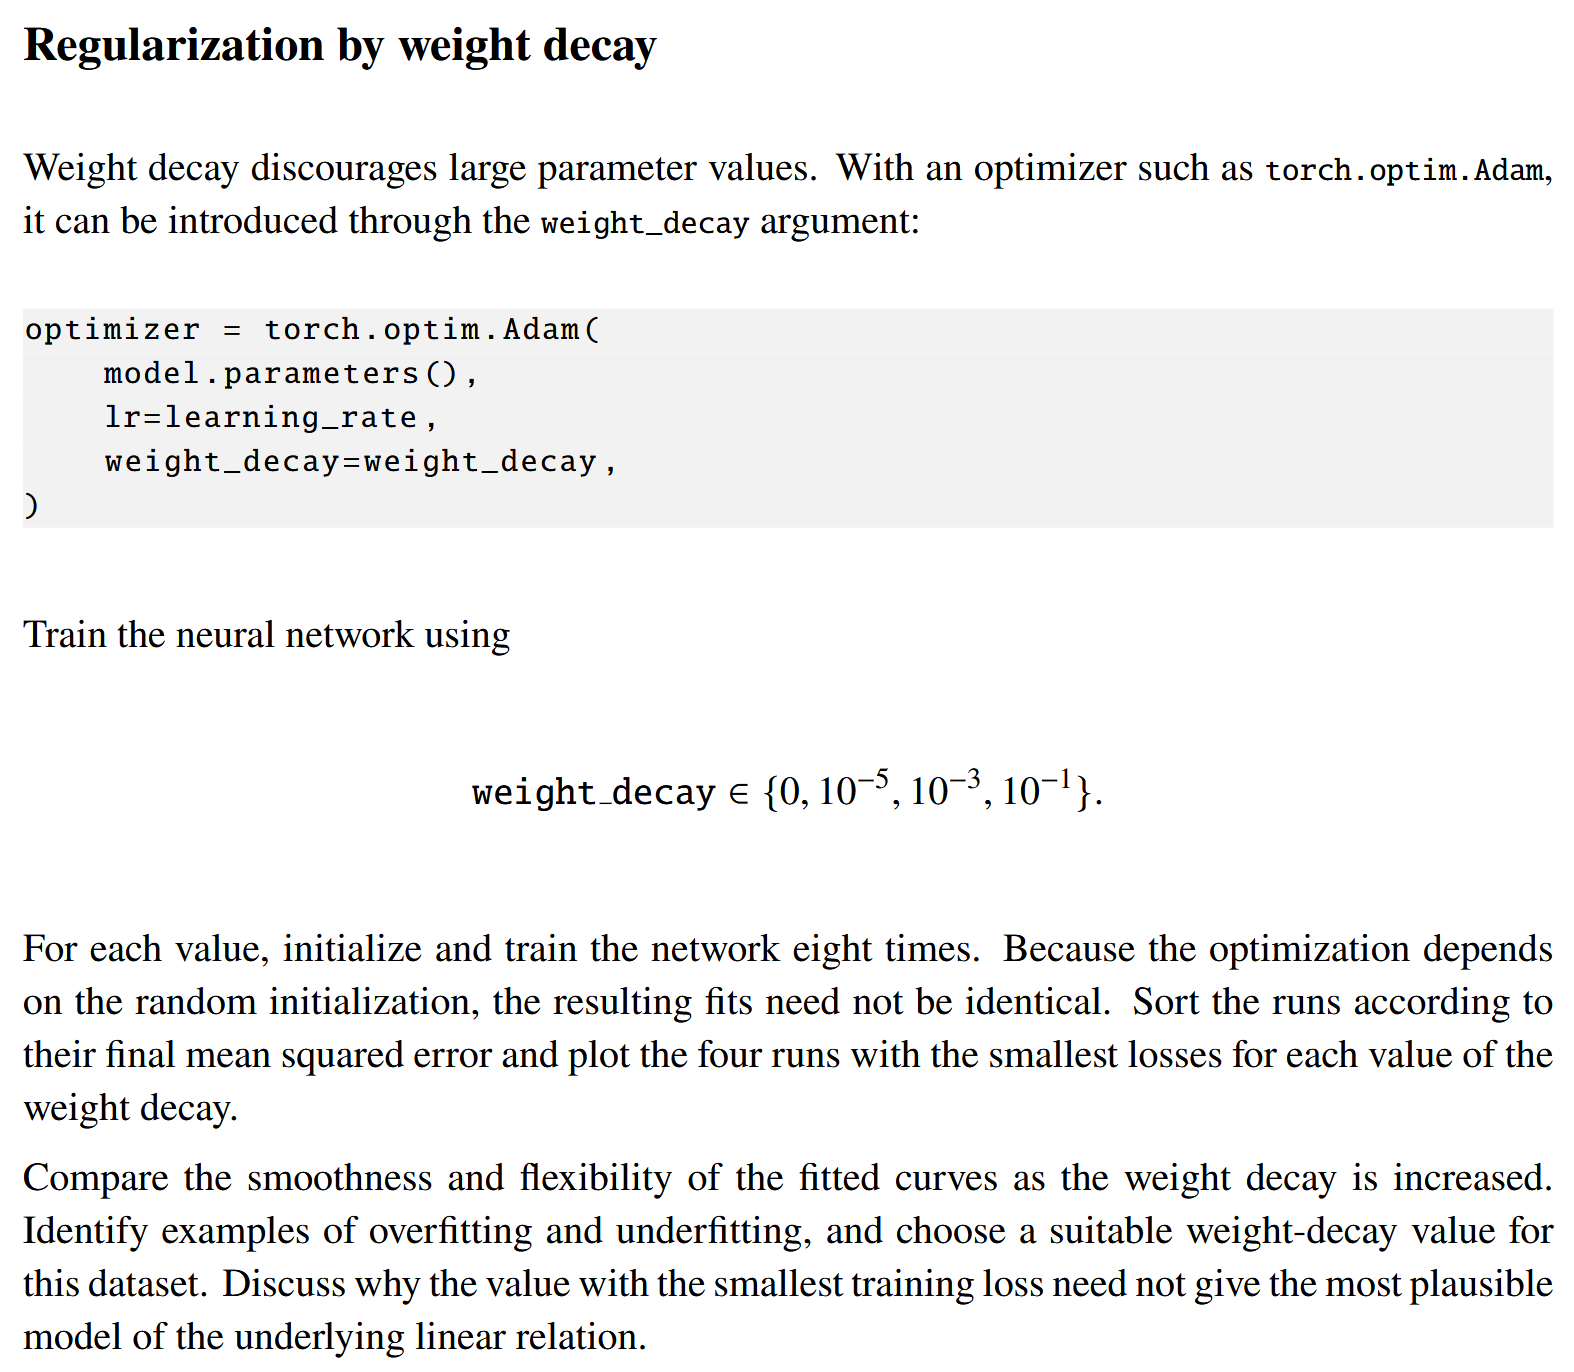

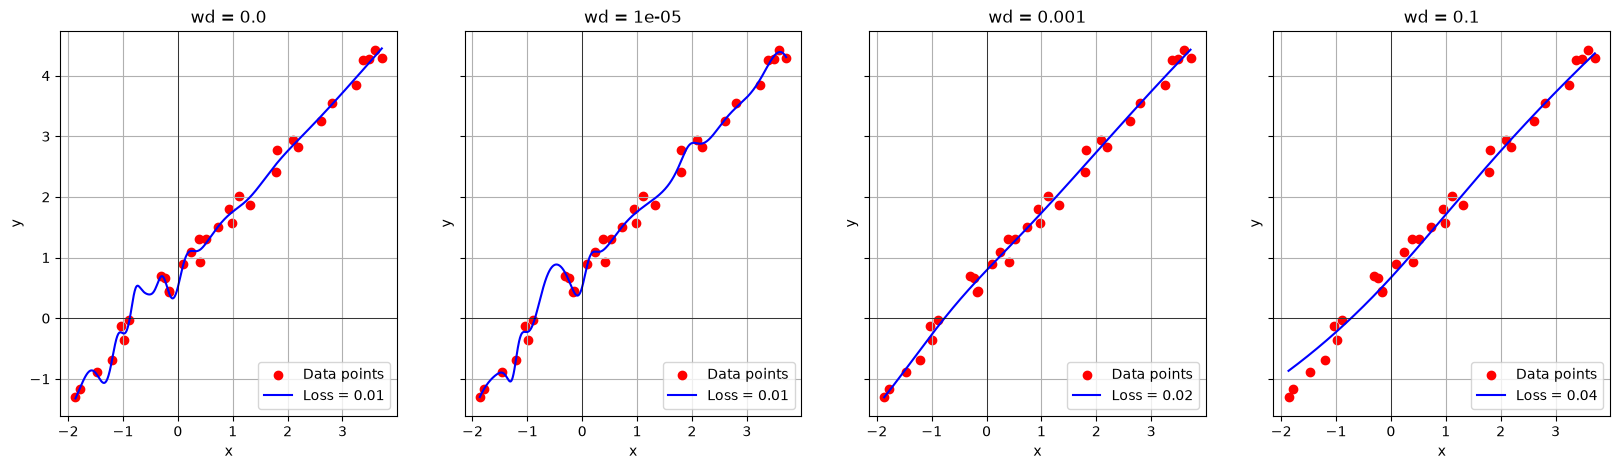

In [4]:
weight_decay = [0.0, 1e-5, 1e-3, 1e-1]

fig, axes = plt.subplots(1, 4, figsize=(20,5), sharey=True)

for wd, ax in zip(weight_decay, axes):
    model = LinearSiLUModule(hidden=8, layers=2)
    model.fit(xs, ys, epochs=10_000, lr=0.01, weight_decay=wd)
    model.plot(ax, xs, ys)
    loss = model.lossFunc(model(xs), ys)
    ax.set_title(f'wd = {wd}')